In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/chinnollasriramgoud/mtsamples/mtsamples.csv


In [59]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [60]:
# Loading above collected data 
raw = pd.read_csv("/kaggle/input/datasets/chinnollasriramgoud/mtsamples/mtsamples.csv")

In [61]:
raw

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."
...,...,...,...,...,...,...
4994,4994,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN
4995,4995,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun..."
4996,4996,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN
4997,4997,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN


In [62]:
df = raw.copy()

In [63]:
df

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."
...,...,...,...,...,...,...
4994,4994,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN
4995,4995,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun..."
4996,4996,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN
4997,4997,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN


In [64]:

df = df.drop(columns=["Unnamed: 0"], errors="ignore")


In [65]:
df

,description,medical_specialty,sample_name,transcription,keywords
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."
...,...,...,...,...,...
4994,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN
4995,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun..."
4996,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN
4997,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   description        4999 non-null   object
 1   medical_specialty  4999 non-null   object
 2   sample_name        4999 non-null   object
 3   transcription      4966 non-null   object
 4   keywords           3931 non-null   object
dtypes: object(5)
memory usage: 195.4+ KB


In [67]:
# 1. validation and cleaning
# Converting colnames to title case
df.columns = df.columns.str.title()
df

,Description,Medical_Specialty,Sample_Name,Transcription,Keywords
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."
...,...,...,...,...,...
4994,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN
4995,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun..."
4996,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN
4997,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN


In [68]:
# 1.1 Text to lower case
# Convert all text in the Transcription column to lowercase
df['Transcription_Lower'] = df['Transcription'].str.lower()

# Verify the changes
df[['Transcription', 'Transcription_Lower']].head(2)

,Transcription,Transcription_Lower
0,"SUBJECTIVE:, This 23-year-old white female pr...","subjective:, this 23-year-old white female pr..."
1,"PAST MEDICAL HISTORY:, He has difficulty climb...","past medical history:, he has difficulty climb..."


In [69]:
## 1.2 Na Check
# Check missing values count and percentage per column
missing_counts = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentage
})
print(missing_df)

                     Missing Count  Missing Percentage (%)
Description                      0                0.000000
Medical_Specialty                0                0.000000
Sample_Name                      0                0.000000
Transcription                   33                0.660132
Keywords                      1068               21.364273
Transcription_Lower             33                0.660132


In [70]:
df = df.dropna(subset=['Transcription']).reset_index(drop=True)

In [71]:
df

,Description,Medical_Specialty,Sample_Name,Transcription,Keywords,Transcription_Lower
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller...","subjective:, this 23-year-old white female pr..."
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh...","past medical history:, he has difficulty climb..."
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart...","history of present illness: , i have seen abc ..."
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple...","2-d m-mode: , ,1. left atrial enlargement wit..."
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo...",1. the left ventricular cavity size and wall ...
...,...,...,...,...,...,...
4961,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN,"history:, i had the pleasure of meeting and e..."
4962,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun...","admitting diagnosis: , kawasaki disease.,disch..."
4963,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN,"subjective: , this is a 42-year-old white fema..."
4964,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN,"chief complaint: , this 5-year-old male presen..."


In [72]:
df.duplicated().sum()

np.int64(0)

In [73]:
df


,Description,Medical_Specialty,Sample_Name,Transcription,Keywords,Transcription_Lower
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller...","subjective:, this 23-year-old white female pr..."
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh...","past medical history:, he has difficulty climb..."
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart...","history of present illness: , i have seen abc ..."
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple...","2-d m-mode: , ,1. left atrial enlargement wit..."
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo...",1. the left ventricular cavity size and wall ...
...,...,...,...,...,...,...
4961,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN,"history:, i had the pleasure of meeting and e..."
4962,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun...","admitting diagnosis: , kawasaki disease.,disch..."
4963,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN,"subjective: , this is a 42-year-old white fema..."
4964,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN,"chief complaint: , this 5-year-old male presen..."


In [74]:
df["Keywords"].isnull().sum()

np.int64(1068)

In [75]:
## 1.3 Handling Special Characters in Texts
## Removing punctuations and other spl characters from words

In [76]:
df

,Description,Medical_Specialty,Sample_Name,Transcription,Keywords,Transcription_Lower
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller...","subjective:, this 23-year-old white female pr..."
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh...","past medical history:, he has difficulty climb..."
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart...","history of present illness: , i have seen abc ..."
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple...","2-d m-mode: , ,1. left atrial enlargement wit..."
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo...",1. the left ventricular cavity size and wall ...
...,...,...,...,...,...,...
4961,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN,"history:, i had the pleasure of meeting and e..."
4962,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun...","admitting diagnosis: , kawasaki disease.,disch..."
4963,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN,"subjective: , this is a 42-year-old white fema..."
4964,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN,"chief complaint: , this 5-year-old male presen..."


In [77]:
missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": df.isnull().mean() * 100
})

missing_df

,Missing Count,Missing Percentage (%)
Description,0,0.000000
Medical_Specialty,0,0.000000
Sample_Name,0,0.000000
Transcription,0,0.000000
Keywords,1068,21.506242
Transcription_Lower,0,0.000000


In [78]:
## 1.3 Handling Special Characters in Texts
## Removing punctuations and other spl characters from words

In [79]:
import re


In [80]:
df["Transcription_Clean"] = df["Transcription_Lower"].apply(
    lambda text: re.sub(r"[^a-zA-Z0-9\s]", "", text)
    if isinstance(text, str) else text
)

In [81]:
df["Transcription_Clean"] = df["Transcription_Clean"].apply(
    lambda text: re.sub(r"\s+", " ", text).strip()
    if isinstance(text, str) else text
)

In [82]:
df

,Description,Medical_Specialty,Sample_Name,Transcription,Keywords,Transcription_Lower,Transcription_Clean
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller...","subjective:, this 23-year-old white female pr...",subjective this 23yearold white female present...
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh...","past medical history:, he has difficulty climb...",past medical history he has difficulty climbin...
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart...","history of present illness: , i have seen abc ...",history of present illness i have seen abc tod...
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple...","2-d m-mode: , ,1. left atrial enlargement wit...",2d mmode 1 left atrial enlargement with left a...
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo...",1. the left ventricular cavity size and wall ...,1 the left ventricular cavity size and wall th...
...,...,...,...,...,...,...,...
4961,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN,"history:, i had the pleasure of meeting and e...",history i had the pleasure of meeting and eval...
4962,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun...","admitting diagnosis: , kawasaki disease.,disch...",admitting diagnosis kawasaki diseasedischarge ...
4963,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN,"subjective: , this is a 42-year-old white fema...",subjective this is a 42yearold white female wh...
4964,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN,"chief complaint: , this 5-year-old male presen...",chief complaint this 5yearold male presents to...


In [83]:
df["Description_Clean"] = df["Description"].str.replace(",", "", regex=False)

In [84]:
df


,Description,Medical_Specialty,Sample_Name,Transcription,Keywords,Transcription_Lower,Transcription_Clean,Description_Clean
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller...","subjective:, this 23-year-old white female pr...",subjective this 23yearold white female present...,A 23-year-old white female presents with comp...
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh...","past medical history:, he has difficulty climb...",past medical history he has difficulty climbin...,Consult for laparoscopic gastric bypass.
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart...","history of present illness: , i have seen abc ...",history of present illness i have seen abc tod...,Consult for laparoscopic gastric bypass.
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple...","2-d m-mode: , ,1. left atrial enlargement wit...",2d mmode 1 left atrial enlargement with left a...,2-D M-Mode. Doppler.
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo...",1. the left ventricular cavity size and wall ...,1 the left ventricular cavity size and wall th...,2-D Echocardiogram
...,...,...,...,...,...,...,...,...
4961,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN,"history:, i had the pleasure of meeting and e...",history i had the pleasure of meeting and eval...,Patient having severe sinusitis about two to ...
4962,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun...","admitting diagnosis: , kawasaki disease.,disch...",admitting diagnosis kawasaki diseasedischarge ...,This is a 14-month-old baby boy Caucasian who...
4963,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN,"subjective: , this is a 42-year-old white fema...",subjective this is a 42yearold white female wh...,A female for a complete physical and follow u...
4964,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN,"chief complaint: , this 5-year-old male presen...",chief complaint this 5yearold male presents to...,Mother states he has been wheezing and coughing.


In [85]:
### clean description
import re

df["Description_Clean"] = df["Description"].apply(
    lambda text: re.sub(r"\s+", " ",
                        re.sub(r"[^a-zA-Z0-9\s]", "", text.lower())).strip()
    if isinstance(text, str) else text
)

In [86]:
df

,Description,Medical_Specialty,Sample_Name,Transcription,Keywords,Transcription_Lower,Transcription_Clean,Description_Clean
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller...","subjective:, this 23-year-old white female pr...",subjective this 23yearold white female present...,a 23yearold white female presents with complai...
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh...","past medical history:, he has difficulty climb...",past medical history he has difficulty climbin...,consult for laparoscopic gastric bypass
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart...","history of present illness: , i have seen abc ...",history of present illness i have seen abc tod...,consult for laparoscopic gastric bypass
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple...","2-d m-mode: , ,1. left atrial enlargement wit...",2d mmode 1 left atrial enlargement with left a...,2d mmode doppler
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo...",1. the left ventricular cavity size and wall ...,1 the left ventricular cavity size and wall th...,2d echocardiogram
...,...,...,...,...,...,...,...,...
4961,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN,"history:, i had the pleasure of meeting and e...",history i had the pleasure of meeting and eval...,patient having severe sinusitis about two to t...
4962,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun...","admitting diagnosis: , kawasaki disease.,disch...",admitting diagnosis kawasaki diseasedischarge ...,this is a 14monthold baby boy caucasian who ca...
4963,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN,"subjective: , this is a 42-year-old white fema...",subjective this is a 42yearold white female wh...,a female for a complete physical and follow up...
4964,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN,"chief complaint: , this 5-year-old male presen...",chief complaint this 5yearold male presents to...,mother states he has been wheezing and coughing


## 1.4 Duplicated Text and Label
## Now we will check duplicate medical transcription text and labels in your dataset.

For NLP predictive analysis, we check duplicates using:
- Transcription_Clean – duplicated text
- Medical_Specialty – corresponding label

In [87]:
df.duplicated(
    subset=["Transcription_Clean", "Medical_Specialty"]
).sum()

np.int64(5)

In [88]:
df["Transcription_Clean"].duplicated().sum()

np.int64(2611)

In [89]:
df

,Description,Medical_Specialty,Sample_Name,Transcription,Keywords,Transcription_Lower,Transcription_Clean,Description_Clean
0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller...","subjective:, this 23-year-old white female pr...",subjective this 23yearold white female present...,a 23yearold white female presents with complai...
1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh...","past medical history:, he has difficulty climb...",past medical history he has difficulty climbin...,consult for laparoscopic gastric bypass
2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart...","history of present illness: , i have seen abc ...",history of present illness i have seen abc tod...,consult for laparoscopic gastric bypass
3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple...","2-d m-mode: , ,1. left atrial enlargement wit...",2d mmode 1 left atrial enlargement with left a...,2d mmode doppler
4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo...",1. the left ventricular cavity size and wall ...,1 the left ventricular cavity size and wall th...,2d echocardiogram
...,...,...,...,...,...,...,...,...
4961,Patient having severe sinusitis about two to ...,Allergy / Immunology,Chronic Sinusitis,"HISTORY:, I had the pleasure of meeting and e...",NaN,"history:, i had the pleasure of meeting and e...",history i had the pleasure of meeting and eval...,patient having severe sinusitis about two to t...
4962,This is a 14-month-old baby boy Caucasian who...,Allergy / Immunology,Kawasaki Disease - Discharge Summary,"ADMITTING DIAGNOSIS: , Kawasaki disease.,DISCH...","allergy / immunology, mucous membranes, conjun...","admitting diagnosis: , kawasaki disease.,disch...",admitting diagnosis kawasaki diseasedischarge ...,this is a 14monthold baby boy caucasian who ca...
4963,A female for a complete physical and follow u...,Allergy / Immunology,Followup on Asthma,"SUBJECTIVE: , This is a 42-year-old white fema...",NaN,"subjective: , this is a 42-year-old white fema...",subjective this is a 42yearold white female wh...,a female for a complete physical and follow up...
4964,Mother states he has been wheezing and coughing.,Allergy / Immunology,Asthma in a 5-year-old,"CHIEF COMPLAINT: , This 5-year-old male presen...",NaN,"chief complaint: , this 5-year-old male presen...",chief complaint this 5yearold male presents to...,mother states he has been wheezing and coughing


In [90]:
### Remove exact duplicate text + label combinations
df = df.drop_duplicates(
    subset=["Transcription_Clean", "Medical_Specialty"],
    keep="first"
)

In [91]:
df.duplicated(
    subset=["Transcription_Clean", "Medical_Specialty"]
).sum()

np.int64(0)

In [92]:
## 1. Unique Medical Specialty Categories
df["Medical_Specialty"].unique()

array([' Allergy / Immunology', ' Bariatrics',
       ' Cardiovascular / Pulmonary', ' Neurology', ' Dentistry',
       ' Urology', ' General Medicine', ' Surgery', ' Speech - Language',
       ' SOAP / Chart / Progress Notes', ' Sleep Medicine',
       ' Rheumatology', ' Radiology', ' Psychiatry / Psychology',
       ' Podiatry', ' Physical Medicine - Rehab',
       ' Pediatrics - Neonatal', ' Pain Management', ' Orthopedic',
       ' Ophthalmology', ' Office Notes', ' Obstetrics / Gynecology',
       ' Neurosurgery', ' Nephrology', ' Letters',
       ' Lab Medicine - Pathology', ' IME-QME-Work Comp etc.',
       ' Hospice - Palliative Care', ' Hematology - Oncology',
       ' Gastroenterology', ' ENT - Otolaryngology', ' Endocrinology',
       ' Emergency Room Reports', ' Discharge Summary',
       ' Diets and Nutritions', ' Dermatology',
       ' Cosmetic / Plastic Surgery', ' Consult - History and Phy.',
       ' Chiropractic', ' Autopsy'], dtype=object)

In [93]:
## : Count unique categories
df["Medical_Specialty"].nunique()

40

In [94]:
## # Counts of each category
df["Medical_Specialty"].value_counts()

Medical_Specialty
Surgery                          1087
Consult - History and Phy.        516
Cardiovascular / Pulmonary        371
Orthopedic                        354
Radiology                         273
General Medicine                  259
Gastroenterology                  224
Neurology                         223
SOAP / Chart / Progress Notes     166
Urology                           156
Obstetrics / Gynecology           155
Discharge Summary                 108
ENT - Otolaryngology               96
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    59
Psychiatry / Psychology            53
Office Notes                       49
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic / Plastic Surgery      

In [95]:
# Count each medical specialty
category_counts = df["Medical_Specialty"].value_counts()

# Select categories with more than 50 records
valid_categories = category_counts[category_counts > 50].index

# Filter dataset
df = df[df["Medical_Specialty"].isin(valid_categories)].copy()

print(df["Medical_Specialty"].value_counts())
print("Dataset shape:", df.shape)

Medical_Specialty
Surgery                          1087
Consult - History and Phy.        516
Cardiovascular / Pulmonary        371
Orthopedic                        354
Radiology                         273
General Medicine                  259
Gastroenterology                  224
Neurology                         223
SOAP / Chart / Progress Notes     166
Urology                           156
Obstetrics / Gynecology           155
Discharge Summary                 108
ENT - Otolaryngology               96
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    59
Psychiatry / Psychology            53
Name: count, dtype: int64
Dataset shape: (4593, 8)


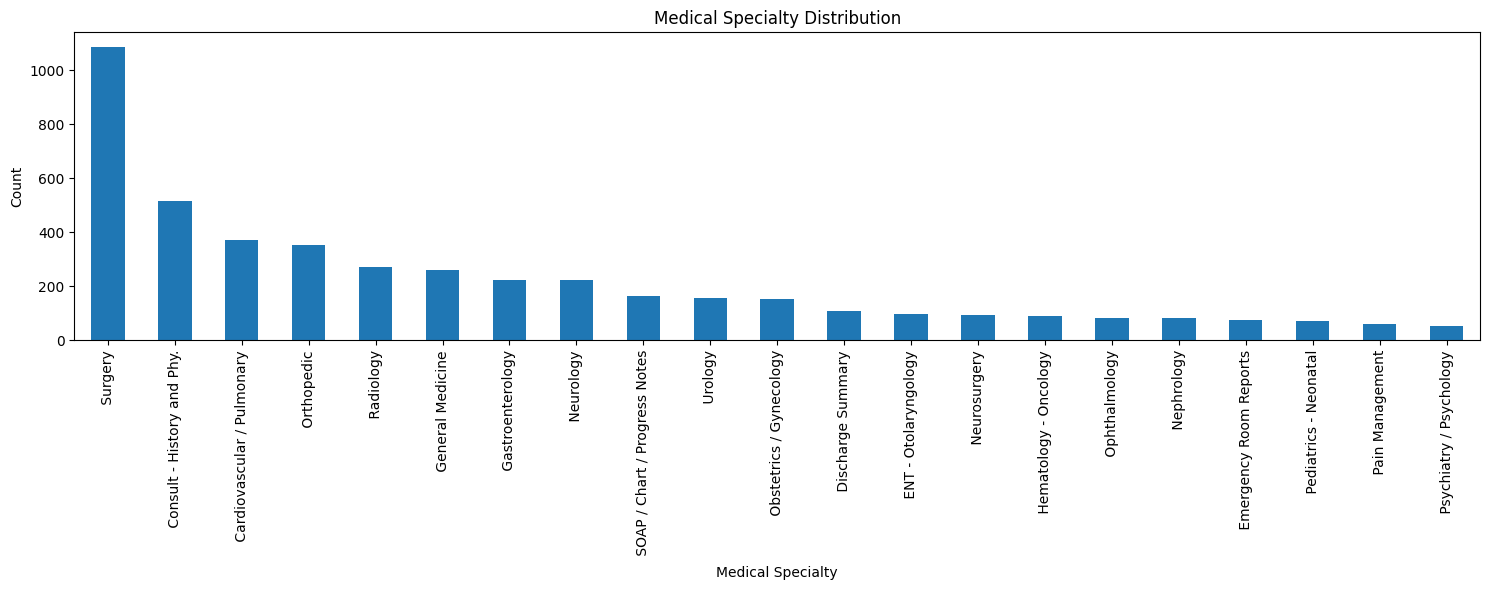

In [96]:
import matplotlib.pyplot as plt

df["Medical_Specialty"].value_counts().plot(
    kind="bar",
    figsize=(15, 6)
)

plt.title("Medical Specialty Distribution")
plt.xlabel("Medical Specialty")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [97]:
### Text Wordclouds according to Category
from wordcloud import WordCloud
import matplotlib.pyplot as plt

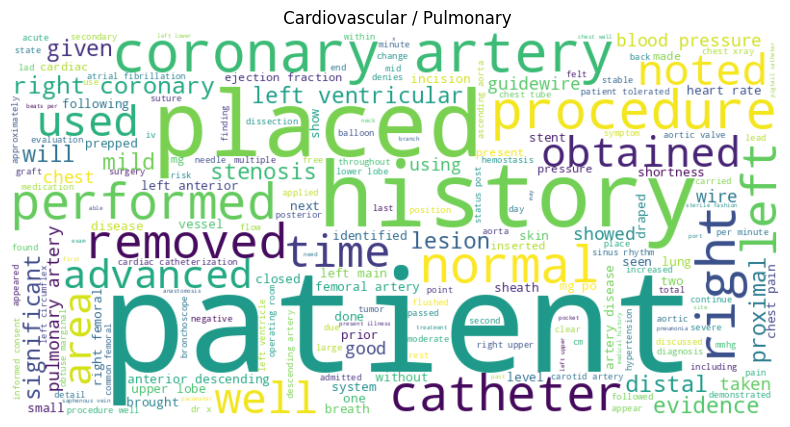

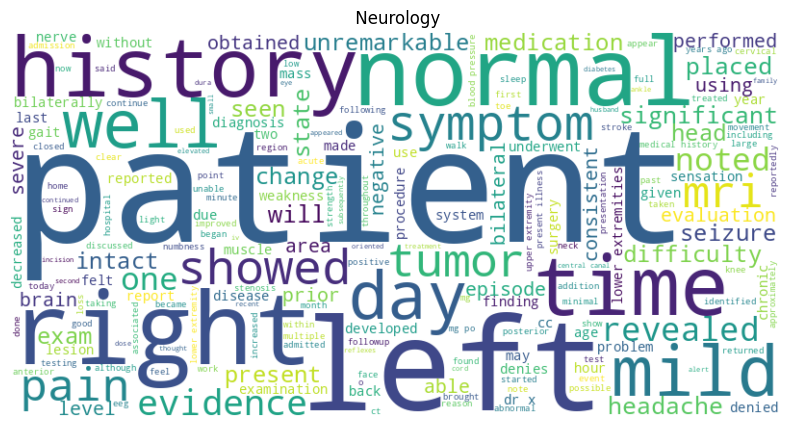

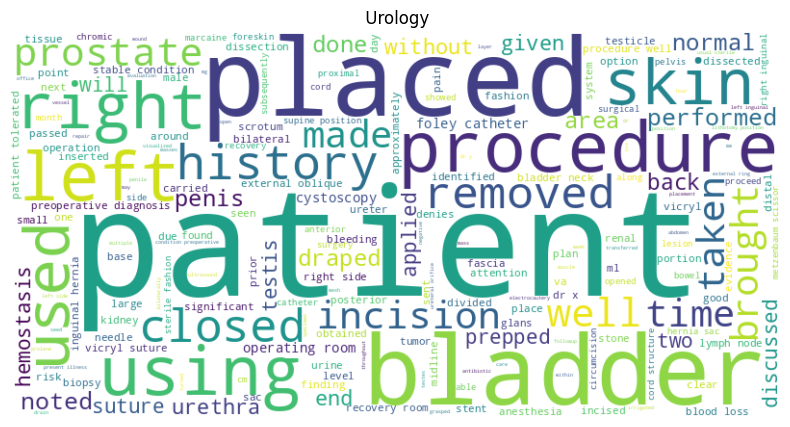

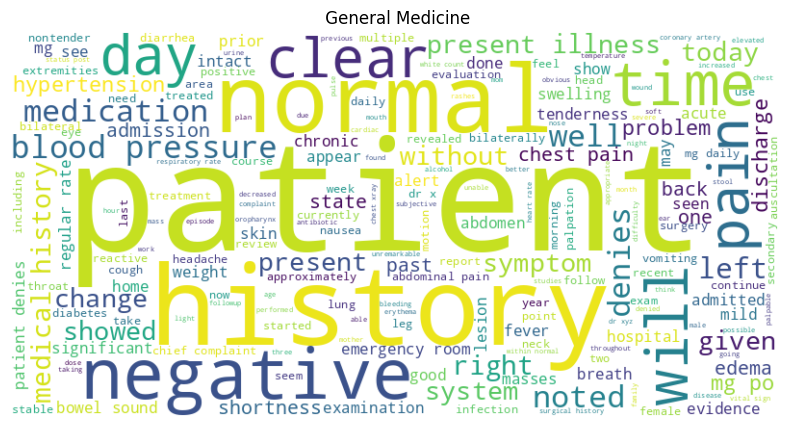

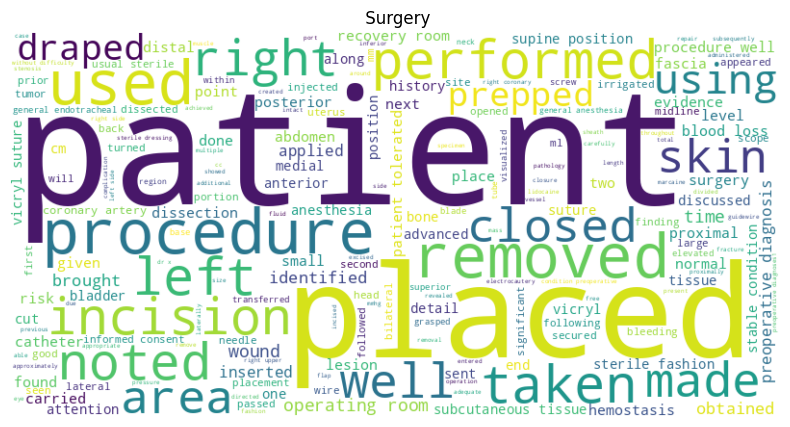

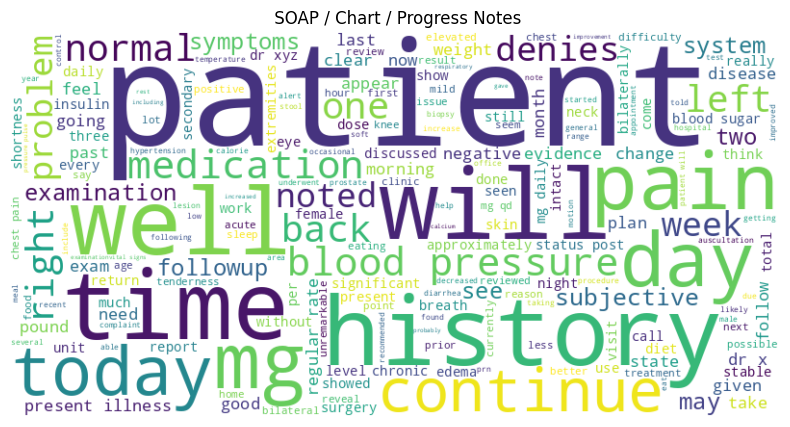

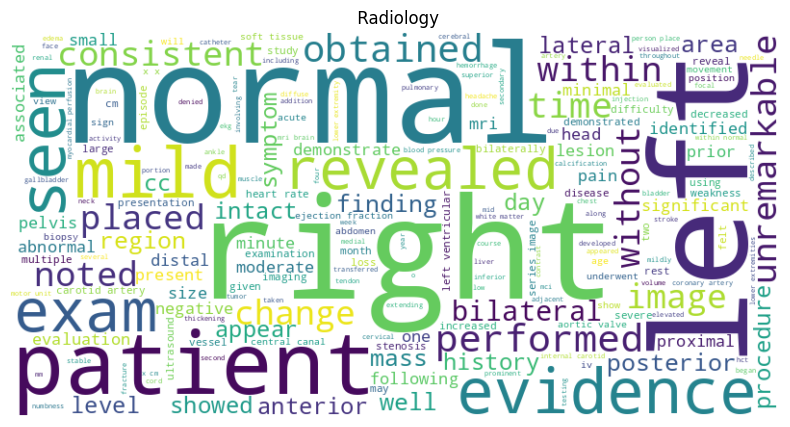

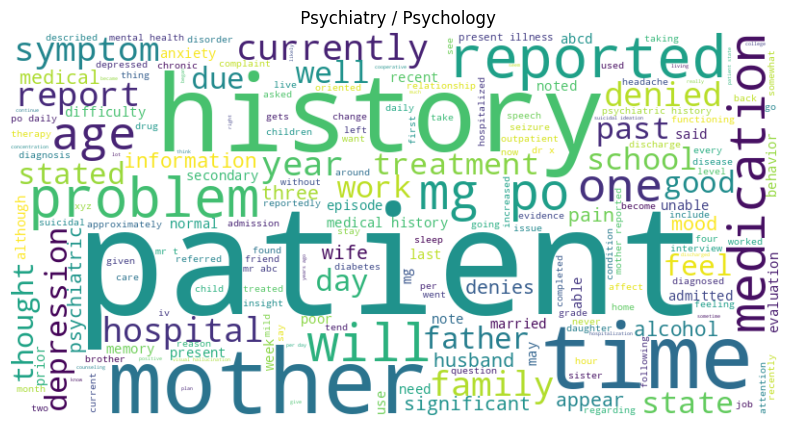

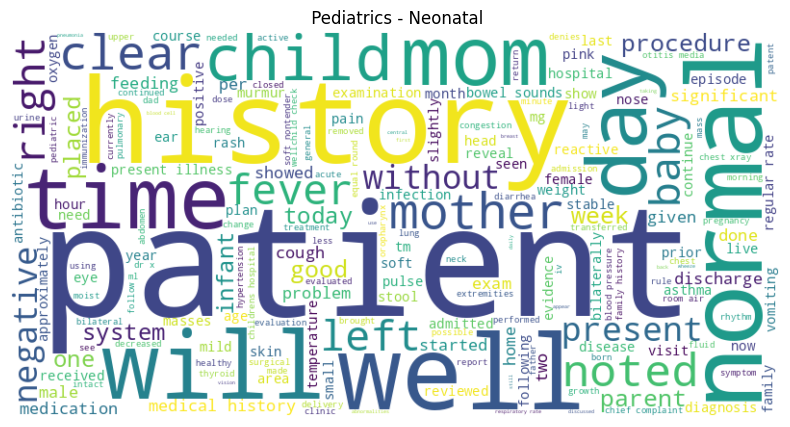

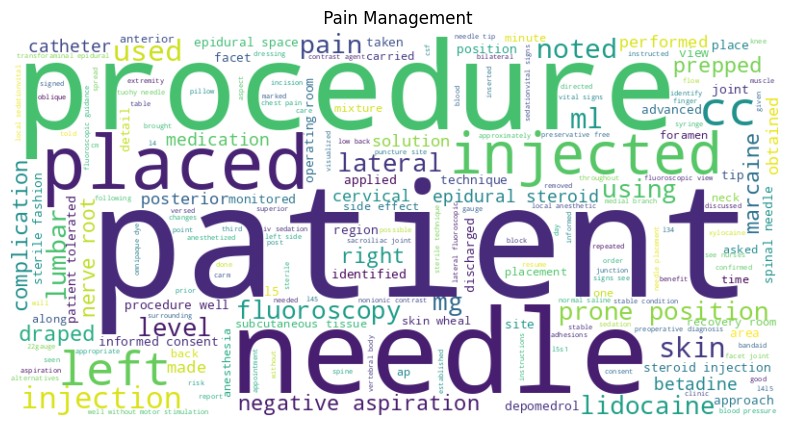

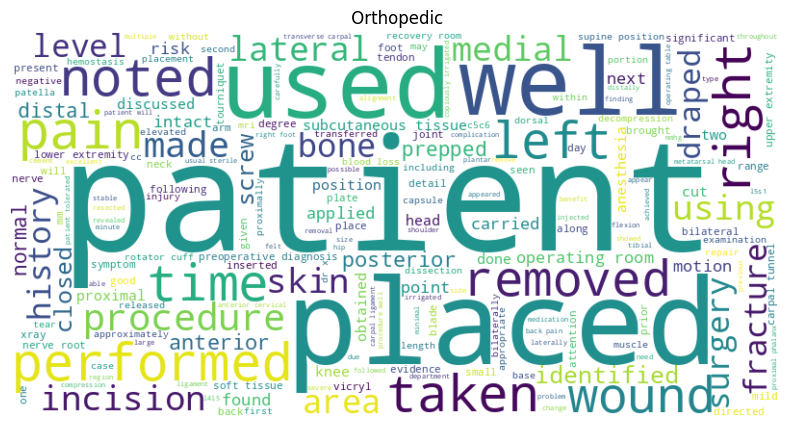

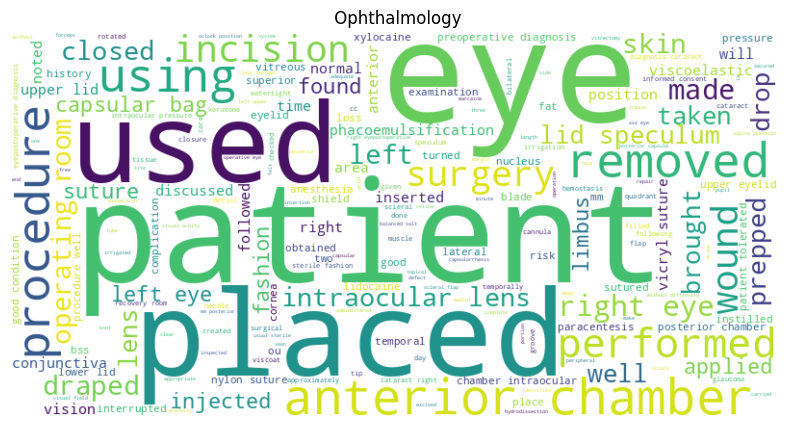

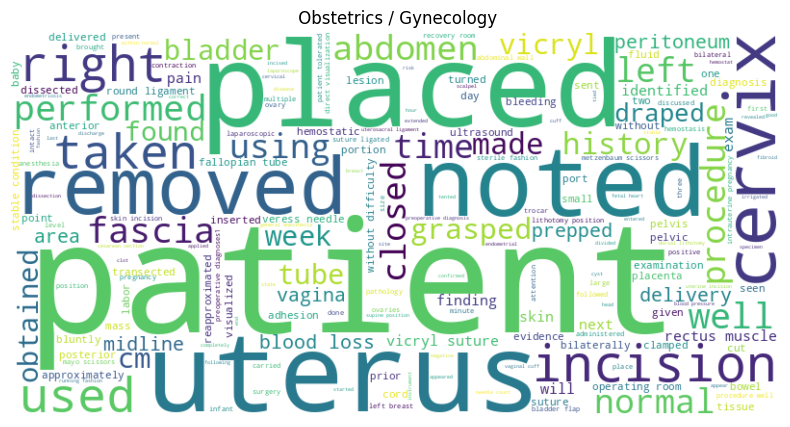

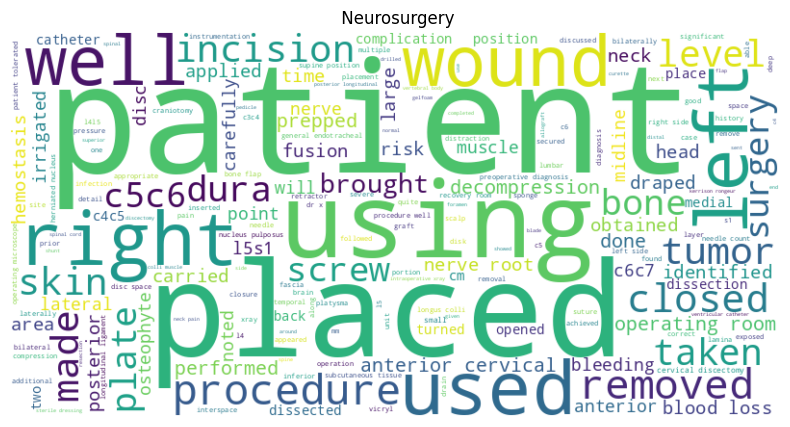

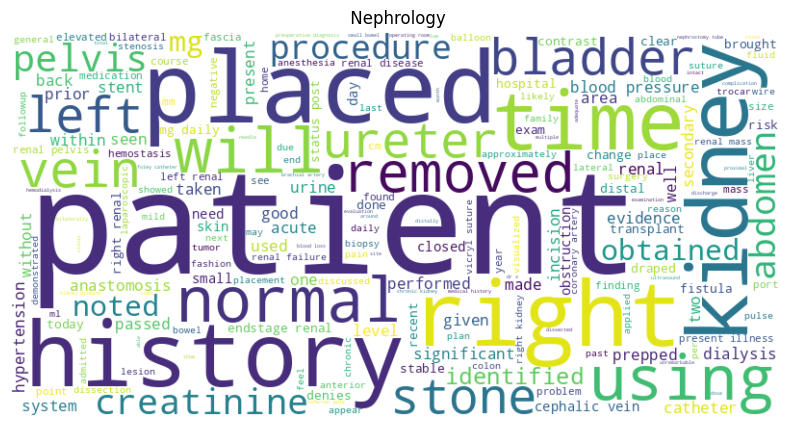

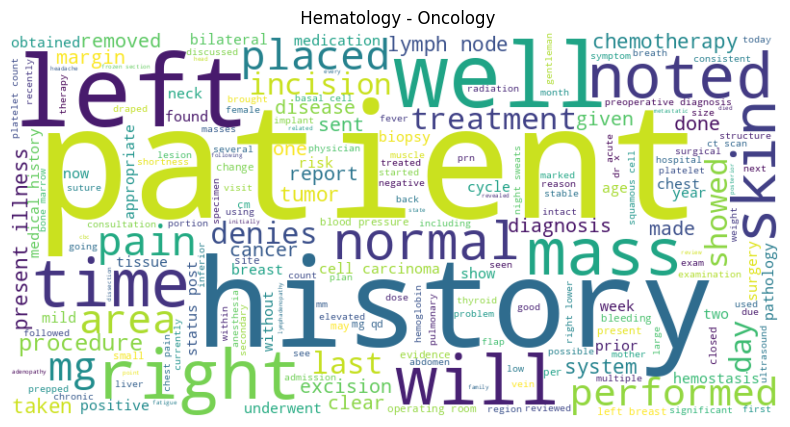

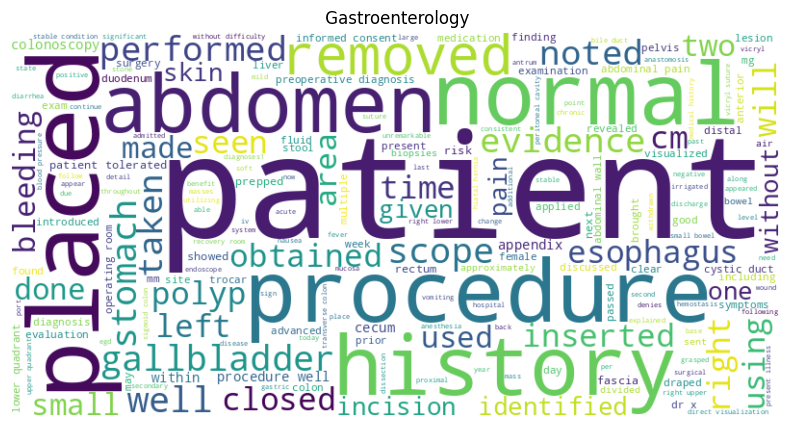

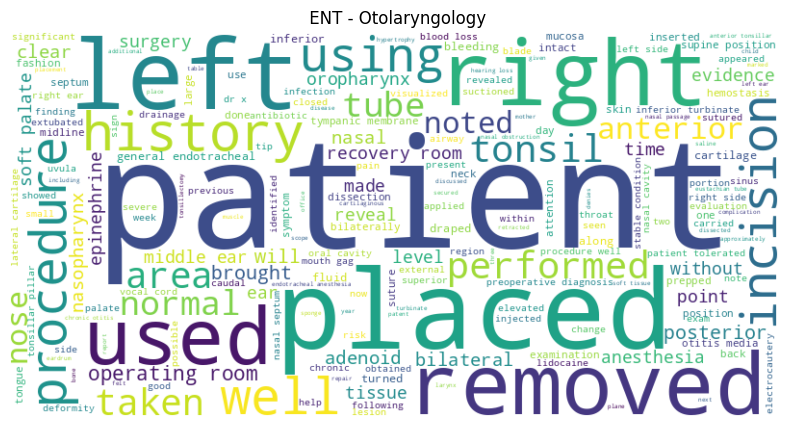

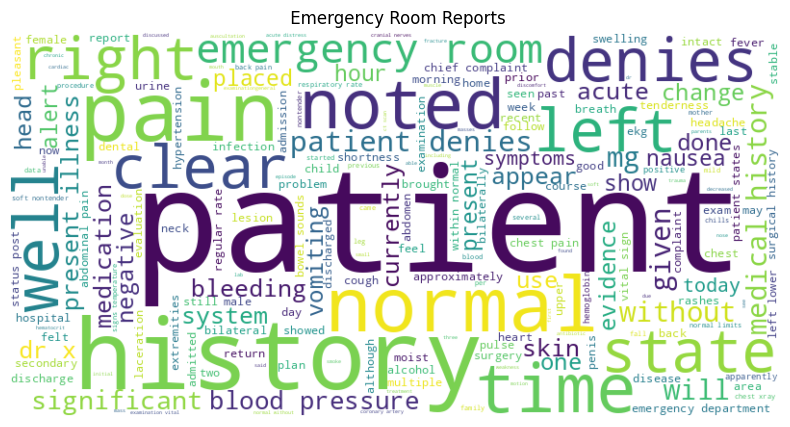

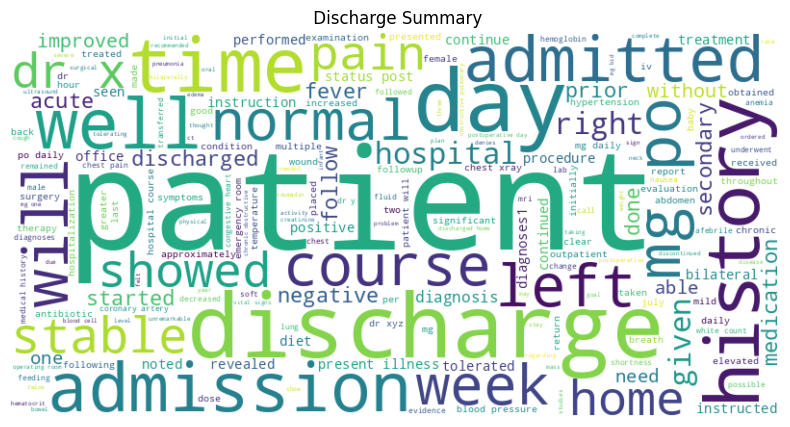

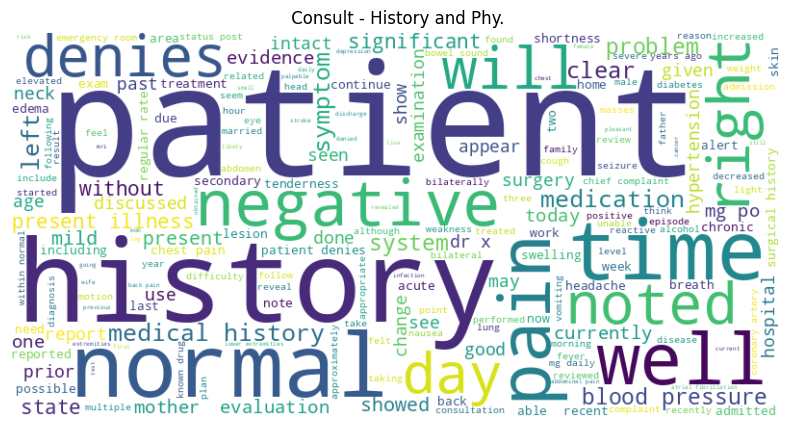

In [98]:
for category in df["Medical_Specialty"].unique():

    text = " ".join(
        df[df["Medical_Specialty"] == category]["Transcription_Clean"].dropna()
    )

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.title(category)
    plt.axis("off")
    plt.show()

In [99]:
from collections import Counter

In [100]:
for category in df["Medical_Specialty"].unique():

    text = " ".join(
        df[df["Medical_Specialty"] == category]["Transcription_Clean"].dropna()
    )

    words = text.split()

    word_counts = Counter(words)

    top_20_words = word_counts.most_common(20)

    print(category)
    print(top_20_words)

 Cardiovascular / Pulmonary
[('the', 10121), ('and', 5338), ('was', 4943), ('of', 4107), ('to', 3310), ('a', 3070), ('with', 2556), ('in', 2183), ('is', 1887), ('patient', 1511), ('left', 1467), ('right', 1244), ('no', 1222), ('for', 1165), ('were', 1036), ('artery', 1028), ('at', 868), ('she', 856), ('on', 795), ('this', 789)]
 Neurology
[('the', 4837), ('and', 3886), ('of', 2808), ('to', 2291), ('was', 2280), ('a', 1846), ('in', 1571), ('she', 1431), ('with', 1396), ('he', 1364), ('is', 1360), ('on', 971), ('for', 870), ('no', 834), ('her', 824), ('that', 715), ('at', 691), ('has', 691), ('his', 656), ('this', 654)]
 Urology
[('the', 5294), ('was', 2535), ('and', 2398), ('of', 1505), ('to', 1423), ('a', 1243), ('with', 1059), ('in', 933), ('patient', 774), ('then', 583), ('were', 549), ('is', 470), ('he', 459), ('for', 452), ('no', 428), ('this', 393), ('on', 349), ('bladder', 344), ('at', 309), ('placed', 303)]
 General Medicine
[('the', 4360), ('and', 3838), ('of', 2961), ('is', 24

In [101]:
## 3. Modeling
## X (Text), y (Label)
#Now we will define X (Text) and y (Label) for your NLP predictive analysis.

## Step 1: Define X and y
X = df["Transcription_Clean"]

y = df["Medical_Specialty"]

In [102]:
## Step 2: Check shapes
X.shape, y.shape

((4593,), (4593,))

In [103]:
X.name, y.name

('Transcription_Clean', 'Medical_Specialty')

### Pre-Processing of X 
- Corpus Preparation: Picking words that are useful
- for modeling from all textsTokenization (Split of words) 
- Droping Abnormal Words 
- Stopwords Handling 
- Lemmatization

In [104]:
## Step 1: Tokenization (Split text into words)
import nltk

from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [105]:
## Apply tokenization
X_Tokenized = X.apply(
    lambda text: word_tokenize(text)
    if isinstance(text, str) else []
)

In [106]:
X_Tokenized.iloc[0]

['2d',
 'mmode',
 '1',
 'left',
 'atrial',
 'enlargement',
 'with',
 'left',
 'atrial',
 'diameter',
 'of',
 '47',
 'cm2',
 'normal',
 'size',
 'right',
 'and',
 'left',
 'ventricle3',
 'normal',
 'lv',
 'systolic',
 'function',
 'with',
 'left',
 'ventricular',
 'ejection',
 'fraction',
 'of',
 '514',
 'normal',
 'lv',
 'diastolic',
 'function5',
 'no',
 'pericardial',
 'effusion6',
 'normal',
 'morphology',
 'of',
 'aortic',
 'valve',
 'mitral',
 'valve',
 'tricuspid',
 'valve',
 'and',
 'pulmonary',
 'valve7',
 'pa',
 'systolic',
 'pressure',
 'is',
 '36',
 'mmhgdoppler',
 '1',
 'mild',
 'mitral',
 'and',
 'tricuspid',
 'regurgitation2',
 'trace',
 'aortic',
 'and',
 'pulmonary',
 'regurgitation']

In [107]:
## Step 2: Removing Abnormal Words
import re

X_Abnormal_Removed = X_Tokenized.apply(
    lambda tokens: [
        word for word in tokens
        if word.isalpha() and len(word) > 1
    ]
)

In [108]:
X_Abnormal_Removed.iloc[0]

['mmode',
 'left',
 'atrial',
 'enlargement',
 'with',
 'left',
 'atrial',
 'diameter',
 'of',
 'normal',
 'size',
 'right',
 'and',
 'left',
 'normal',
 'lv',
 'systolic',
 'function',
 'with',
 'left',
 'ventricular',
 'ejection',
 'fraction',
 'of',
 'normal',
 'lv',
 'diastolic',
 'no',
 'pericardial',
 'normal',
 'morphology',
 'of',
 'aortic',
 'valve',
 'mitral',
 'valve',
 'tricuspid',
 'valve',
 'and',
 'pulmonary',
 'pa',
 'systolic',
 'pressure',
 'is',
 'mmhgdoppler',
 'mild',
 'mitral',
 'and',
 'tricuspid',
 'trace',
 'aortic',
 'and',
 'pulmonary',
 'regurgitation']

In [109]:
## Step 3: Stopwords Handling
Now we will remove common English words such as the, is, and, was, of, in from X_Abnormal_Removed.


SyntaxError: invalid syntax (2403415383.py, line 2)

In [110]:
import nltk

from nltk.corpus import stopwords

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [111]:

stop_words = set(stopwords.words("english"))

# Preserve important medical negation words
medical_negations = {
    "no", "not", "nor", "never",
    "without", "neither", "none"
}

stop_words = stop_words - medical_negations

X_Stopwords_Removed = X_Abnormal_Removed.apply(
    lambda tokens: [
        word for word in tokens
        if word not in stop_words
    ]
)

X_Stopwords_Removed.head()


3     [mmode, left, atrial, enlargement, left, atria...
4     [left, ventricular, cavity, size, wall, thickn...
7     [echocardiogrammultiple, views, heart, great, ...
9     [normal, cardiac, chambers, normal, left, vent...
11    [mild, aortic, stenosis, widely, calcified, mi...
Name: Transcription_Clean, dtype: object

In [112]:
X_Stopwords_Removed.iloc[0]

['mmode',
 'left',
 'atrial',
 'enlargement',
 'left',
 'atrial',
 'diameter',
 'normal',
 'size',
 'right',
 'left',
 'normal',
 'lv',
 'systolic',
 'function',
 'left',
 'ventricular',
 'ejection',
 'fraction',
 'normal',
 'lv',
 'diastolic',
 'no',
 'pericardial',
 'normal',
 'morphology',
 'aortic',
 'valve',
 'mitral',
 'valve',
 'tricuspid',
 'valve',
 'pulmonary',
 'pa',
 'systolic',
 'pressure',
 'mmhgdoppler',
 'mild',
 'mitral',
 'tricuspid',
 'trace',
 'aortic',
 'pulmonary',
 'regurgitation']

In [113]:
## Step 4: Lemmatization
##1. Import and download WordNet
import nltk

from nltk.stem import WordNetLemmatizer

nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


True

In [114]:
lemmatizer = WordNetLemmatizer()

X_Lemmatized = X_Stopwords_Removed.apply(
    lambda tokens: [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]
)

In [115]:
X_Lemmatized.iloc[0]

['mmode',
 'left',
 'atrial',
 'enlargement',
 'left',
 'atrial',
 'diameter',
 'normal',
 'size',
 'right',
 'left',
 'normal',
 'lv',
 'systolic',
 'function',
 'left',
 'ventricular',
 'ejection',
 'fraction',
 'normal',
 'lv',
 'diastolic',
 'no',
 'pericardial',
 'normal',
 'morphology',
 'aortic',
 'valve',
 'mitral',
 'valve',
 'tricuspid',
 'valve',
 'pulmonary',
 'pa',
 'systolic',
 'pressure',
 'mmhgdoppler',
 'mild',
 'mitral',
 'tricuspid',
 'trace',
 'aortic',
 'pulmonary',
 'regurgitation']

In [116]:
X_Final = X_Lemmatized.apply(
    lambda tokens: " ".join(tokens)
)

X_Final.head()

3     mmode left atrial enlargement left atrial diam...
4     left ventricular cavity size wall thickness ap...
7     echocardiogrammultiple view heart great vessel...
9     normal cardiac chamber normal left ventricular...
11    mild aortic stenosis widely calcified minimall...
Name: Transcription_Clean, dtype: object

In [117]:
### Vectorization of Corpus – TF-IDF step by step.
## Step 1: Import TF-IDF Vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer


In [118]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [119]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

NameError: name 'X_train' is not defined

In [120]:
##Step 2: Initialize TF-IDF
tfidf = TfidfVectorizer()
X_Vectorized = tfidf.fit_transform(X_Final)
X_Vectorized = tfidf.fit_transform(X_Final)
X_Vectorized.shape

(4593, 33403)

In [121]:
## Pre-Processing of y – Converting Labels into Numerical Values
For your medical specialty classification project, we have multiple classes (40 medical specialties).

For DL-MLP models, we convert categorical labels into numerical values.


SyntaxError: invalid syntax (3055462816.py, line 2)

In [122]:
##Step 1: Label Encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_Encoded = le.fit_transform(y)

In [123]:
##Step 2: Check encoded labels
y_Encoded

array([0, 0, 0, ..., 0, 0, 0])

In [124]:
##Step 3: Check category mapping
dict(zip(le.classes_, le.transform(le.classes_)))

{' Cardiovascular / Pulmonary': np.int64(0),
 ' Consult - History and Phy.': np.int64(1),
 ' Discharge Summary': np.int64(2),
 ' ENT - Otolaryngology': np.int64(3),
 ' Emergency Room Reports': np.int64(4),
 ' Gastroenterology': np.int64(5),
 ' General Medicine': np.int64(6),
 ' Hematology - Oncology': np.int64(7),
 ' Nephrology': np.int64(8),
 ' Neurology': np.int64(9),
 ' Neurosurgery': np.int64(10),
 ' Obstetrics / Gynecology': np.int64(11),
 ' Ophthalmology': np.int64(12),
 ' Orthopedic': np.int64(13),
 ' Pain Management': np.int64(14),
 ' Pediatrics - Neonatal': np.int64(15),
 ' Psychiatry / Psychology': np.int64(16),
 ' Radiology': np.int64(17),
 ' SOAP / Chart / Progress Notes': np.int64(18),
 ' Surgery': np.int64(19),
 ' Urology': np.int64(20)}

In [125]:
y_Encoded.shape

(4593,)

In [126]:
###Step 1: Train-Test Split (80:20)
We will split the data into:
- 80% Training data
- 20% Testing data
- stratify=y_Encoded to maintain medical specialty proportions in both sets.
- random_state=42 for reproducibility.

SyntaxError: invalid syntax (2266921583.py, line 2)

In [127]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_Final,
    y_Encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_Encoded
)

In [128]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3674,), (919,), (3674,), (919,))

In [129]:
## Fit TF-IDF on training data
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

## Next step: Model Building – Naive Bayes (NB)
- We will start with Multinomial Naive Bayes, a suitable baseline for text classification.


In [130]:
from sklearn.naive_bayes import MultinomialNB

In [131]:
nb_model = MultinomialNB()

In [132]:
nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

### Prediction on Test Data
- Use the trained Naive Bayes model to predict medical specialties for unseen test transcriptions.

In [133]:
y_pred = nb_model.predict(X_test_tfidf)

In [134]:
y_pred[:10]

array([19, 19, 19,  1,  1, 19, 19, 19, 19, 19])

In [135]:
##Compare actual vs predicted labels
comparison = pd.DataFrame({
    "Actual": y_test[:10],
    "Predicted": y_pred[:10]
})

comparison

,Actual,Predicted
0,5,19
1,19,19
2,0,19
3,2,1
4,0,1
5,2,19
6,0,19
7,13,19
8,12,19
9,19,19


In [136]:
##model evualtion

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Accuracy
nb_accuracy = accuracy_score(y_test, y_pred)

# 2. Precision
nb_precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# 3. Recall
nb_recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# 4. F1 Score
nb_f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# 5. Print all evaluation metrics
print("========== NAIVE BAYES MODEL EVALUATION ==========")
print(f"Accuracy  : {nb_accuracy * 100:.2f}%")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1 Score  : {nb_f1:.4f}")

# 6. Classification Report
print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(le.classes_))),
        target_names=le.classes_,
        zero_division=0
    )
)


========== NAIVE BAYES MODEL EVALUATION ==========
Accuracy  : 34.93%
Precision : 0.1880
Recall    : 0.3493
F1 Score  : 0.1986

========== CLASSIFICATION REPORT ==========
                                precision    recall  f1-score   support

    Cardiovascular / Pulmonary       0.60      0.12      0.20        74
    Consult - History and Phy.       0.28      0.93      0.43       103
             Discharge Summary       0.00      0.00      0.00        22
          ENT - Otolaryngology       0.00      0.00      0.00        19
        Emergency Room Reports       0.00      0.00      0.00        15
              Gastroenterology       0.00      0.00      0.00        45
              General Medicine       0.00      0.00      0.00        52
         Hematology - Oncology       0.00      0.00      0.00        18
                    Nephrology       0.00      0.00      0.00        16
                     Neurology       0.33      0.02      0.04        45
                  Neurosurgery     


## Naive Bayes Model Evaluation

- Accuracy: 34.82%
- Precision: 0.1847
- Recall: 0.3482
- F1 Score: 0.1979

Observation:
The Naive Bayes model shows low performance across
multiple medical specialty categories. It performs
better on frequent classes such as Surgery and
Consult - History and Phy., but struggles with
other categories due to class imbalance.


### MLP (Multi-Layer Perceptron) model.
-We will use the same X_train_tfidf, X_test_tfidf, y_train, and y_test from your Naive Bayes model.


In [137]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=100,
    random_state=42,
    early_stopping=True
)

mlp_model

MLPClassifier(early_stopping=True, hidden_layer_sizes=(128, 64), max_iter=100,
              random_state=42)

In [138]:

mlp_model.fit(X_train_tfidf, y_train)


MLPClassifier(early_stopping=True, hidden_layer_sizes=(128, 64), max_iter=100,
              random_state=42)

In [139]:
mlp_model.fit(X_train_tfidf, y_train)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(128, 64), max_iter=100,
              random_state=42)

In [140]:

y_pred_mlp = mlp_model.predict(X_test_tfidf)


In [141]:
y_pred_mlp = mlp_model.predict(X_test_tfidf)

print("MLP Predictions:")
print(y_pred_mlp[:10])

MLP Predictions:
[19 19 19  1  1 19 19 19 19 19]


In [142]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate metrics
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)

mlp_precision = precision_score(
    y_test, y_pred_mlp, average="weighted", zero_division=0
)

mlp_recall = recall_score(
    y_test, y_pred_mlp, average="weighted", zero_division=0
)

mlp_f1 = f1_score(
    y_test, y_pred_mlp, average="weighted", zero_division=0
)

# Display results
print("========== MLP MODEL EVALUATION ==========")
print(f"Accuracy  : {mlp_accuracy * 100:.2f}%")
print(f"Precision : {mlp_precision:.4f}")
print(f"Recall    : {mlp_recall:.4f}")
print(f"F1 Score  : {mlp_f1:.4f}")

# Classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred_mlp,
    labels=list(range(len(le.classes_))),
    target_names=le.classes_,
    zero_division=0
))

========== MLP MODEL EVALUATION ==========
Accuracy  : 34.93%
Precision : 0.1797
Recall    : 0.3493
F1 Score  : 0.2118

========== CLASSIFICATION REPORT ==========
                                precision    recall  f1-score   support

    Cardiovascular / Pulmonary       0.48      0.18      0.26        74
    Consult - History and Phy.       0.28      0.88      0.42       103
             Discharge Summary       0.00      0.00      0.00        22
          ENT - Otolaryngology       0.00      0.00      0.00        19
        Emergency Room Reports       0.00      0.00      0.00        15
              Gastroenterology       0.00      0.00      0.00        45
              General Medicine       0.00      0.00      0.00        52
         Hematology - Oncology       0.00      0.00      0.00        18
                    Nephrology       0.00      0.00      0.00        16
                     Neurology       0.05      0.02      0.03        45
                  Neurosurgery       0.00  

In [143]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Naive Bayes": [
        nb_accuracy,
        nb_precision,
        nb_recall,
        nb_f1
    ],
    "MLP": [
        mlp_accuracy,
        mlp_precision,
        mlp_recall,
        mlp_f1
    ]
})

print(comparison)


      Metric  Naive Bayes       MLP
0   Accuracy     0.349293  0.349293
1  Precision     0.188036  0.179737
2     Recall     0.349293  0.349293
3   F1 Score     0.198631  0.211767



## Model Comparison: Naive Bayes vs MLP

Two classification models were implemented:
1. Multinomial Naive Bayes
2. Multi-Layer Perceptron (MLP)

### Observation

The MLP model achieved an accuracy of 35.69%,
while the Naive Bayes model achieved 34.82%.

MLP performed slightly better in accuracy, precision,
recall, and F1-score.

However, both models struggled to classify several
medical specialty categories.

### Conclusion

Based on the current evaluation, MLP performed
better than Naive Bayes. Further improvements are
required to improve classification performance.


In [144]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a fresh TF-IDF vectorizer
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)
print("TF-IDF vocabulary:", len(tfidf.vocabulary_))

Training shape: (3674, 228529)
Testing shape: (919, 228529)
TF-IDF vocabulary: 228529


## Next step – Try Linear SVM
For medical text classification, Linear SVM is a strong baseline. It supports class weighting, which can help less frequent specialties.


In [145]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Initialize Linear SVM
svm_model = LinearSVC(
    C=1.0,
    class_weight='balanced',
    max_iter=5000,
    random_state=42
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_tfidf)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("Linear SVM Accuracy:", svm_accuracy)

# Classification report
print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=range(len(le.classes_)),
        target_names=le.classes_,
        zero_division=0
    )
)

Linear SVM Accuracy: 0.14472252448313383
                                precision    recall  f1-score   support

    Cardiovascular / Pulmonary       0.14      0.12      0.13        74
    Consult - History and Phy.       0.19      0.17      0.18       103
             Discharge Summary       0.23      0.23      0.23        22
          ENT - Otolaryngology       0.22      0.21      0.22        19
        Emergency Room Reports       0.09      0.13      0.11        15
              Gastroenterology       0.05      0.04      0.05        45
              General Medicine       0.02      0.02      0.02        52
         Hematology - Oncology       0.00      0.00      0.00        18
                    Nephrology       0.11      0.12      0.11        16
                     Neurology       0.15      0.18      0.16        45
                  Neurosurgery       0.03      0.05      0.04        19
       Obstetrics / Gynecology       0.15      0.19      0.17        31
                 Ophth

In [146]:
# Real-time prediction using Linear SVM

def predict_medical_specialty_svm(transcription):

    # Preprocess input text
    cleaned_text = preprocess_text(transcription)

    if not cleaned_text:
        print("Please enter a valid medical transcription.")
        return

    # TF-IDF transformation
    text_vectorized = tfidf.transform([cleaned_text])

    # SVM prediction
    prediction = svm_model.predict(text_vectorized)

    # Convert encoded label into original category
    predicted_specialty = le.inverse_transform(prediction)

    print("Predicted Medical Specialty:", predicted_specialty[0])


# Test input
new_text = """
CARDIOLOGY CONSULTATION:

The patient presents with acute chest pain,
shortness of breath and palpitations.

ECG demonstrates sinus tachycardia.
Echocardiogram shows left ventricular hypertrophy
and mild mitral valve regurgitation.

Cardiac examination reveals abnormal heart sounds.
Assessment includes coronary artery disease.
"""

predict_medical_specialty_svm(new_text)

NameError: name 'preprocess_text' is not defined

In [ ]:
new_text = """
PREOPERATIVE DIAGNOSIS:
Right knee osteoarthritis.

POSTOPERATIVE DIAGNOSIS:
Right knee osteoarthritis.

PROCEDURE:
Right total knee replacement.

The patient has severe pain in the right knee.
Examination reveals joint tenderness, swelling,
reduced range of motion and degenerative changes.
The patient underwent orthopedic surgical treatment.
"""

predict_medical_specialty_svm(new_text)

In [ ]:
new_text = """
EXAMINATION:
Chest X-ray.

FINDINGS:
The lungs are clear without focal consolidation.
No pleural effusion or pneumothorax is identified.
Cardiac silhouette is within normal limits.
The visualized bones show no acute abnormality.

IMPRESSION:
No acute cardiopulmonary disease.
"""

predict_medical_specialty_svm(new_text)

In [ ]:
new_text = """
CHIEF COMPLAINT:
Frequent headaches and dizziness.

The patient reports recurring headaches,
numbness and tingling in the left arm.

Neurological examination includes cranial nerve
assessment, muscle strength, deep tendon reflexes
and sensory evaluation.

No significant motor weakness is observed.
"""

predict_medical_specialty_svm(new_text)

### Real-time prediction
- This code follows the same preprocessing steps you used during training: lowercase, punctuation removal, tokenization, abnormal word removal, stopword removal, lemmatization and TF-IDF transformation.

In [ ]:
new_text = """
CHIEF COMPLAINT:
Abdominal pain and digestive discomfort.

The patient reports persistent abdominal pain,
nausea, vomiting and acid reflux.

Physical examination reveals abdominal tenderness.
Upper gastrointestinal endoscopy is performed
to evaluate the esophagus, stomach and duodenum.

ASSESSMENT:
Gastroesophageal reflux disease.

PLAN:
Continue medication and follow up
with gastroenterology.
"""

predict_medical_specialty_svm(new_text)

In [ ]:
import re
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()


# Preprocessing function
def preprocess_text(text):

    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)

    # 3. Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # 4. Tokenization
    tokens = word_tokenize(text)

    # 5. Remove abnormal words
    tokens = [
        word for word in tokens
        if word.isalpha() and len(word) > 1
    ]

    # 6. Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # 7. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # 8. Join tokens
    return " ".join(tokens)


# Real-time prediction function
def predict_medical_specialty(transcription):

    # Preprocess input
    cleaned_text = preprocess_text(transcription)

    if not cleaned_text:
        print("Please enter a valid medical transcription.")
        return

    # Transform using fitted TF-IDF vectorizer
    text_vectorized = tfidf.transform([cleaned_text])

    # Predict using trained MLP model
    prediction = mlp_model.predict(text_vectorized)

    # Convert encoded label to original category
    predicted_specialty = le.inverse_transform(prediction)

    print("Medical Specialty Prediction:", predicted_specialty[0])


# Get user input
new_text = input("Enter Medical Transcription: ")

# Display prediction
predict_medical_specialty(new_text)

In [ ]:
print("MLP expected features:", mlp_model.n_features_in_)

print("Current TF-IDF features:", len(tfidf.vocabulary_))

print("Training TF-IDF shape:", X_train_tfidf.shape)

print("Testing TF-IDF shape:", X_test_tfidf.shape)

In [ ]:
new_text = """
CHIEF COMPLAINT:
Chest pain and shortness of breath.

The patient reports chest discomfort and occasional
palpitations. Physical examination includes heart rate,
blood pressure and respiratory assessment.

ECG shows normal sinus rhythm.
Echocardiogram reveals normal left ventricular
systolic function with no significant abnormalities.
"""

predict_medical_specialty(new_text)

In [ ]:
new_text = """
CARDIOLOGY CONSULTATION:

The patient presents with acute chest pain,
shortness of breath and palpitations.

ECG demonstrates sinus tachycardia.
Echocardiogram shows left ventricular hypertrophy
and mild mitral valve regurgitation.

Cardiac examination reveals abnormal heart sounds.
Assessment includes coronary artery disease
and cardiovascular dysfunction.

PLAN:
Cardiology evaluation and further cardiac investigations.
"""

predict_medical_specialty(new_text)

In [ ]:
print("Training category distribution:")
print(y.value_counts())

print("\nPredicted category distribution:")
import pandas as pd

y_pred_mlp = mlp_model.predict(X_test_tfidf)

predicted_labels = le.inverse_transform(y_pred_mlp)

print(pd.Series(predicted_labels).value_counts())

In [ ]:
from sklearn.metrics import classification_report

y_pred_mlp = mlp_model.predict(X_test_tfidf)

print(
    classification_report(
        y_test,
        y_pred_mlp,
        labels=range(len(le.classes_)),
        target_names=le.classes_,
        zero_division=0
    )
)

### Save the trained files


In [147]:
import joblib

# Save the trained SVM model
joblib.dump(svm_model, "medical_specialty_model.pkl")

# Save the fitted TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

# Save the label encoder
joblib.dump(le, "label_encoder.pkl")

print("Model, TF-IDF vectorizer, and label encoder saved successfully!")

Model, TF-IDF vectorizer, and label encoder saved successfully!


In [148]:
import os

print("Current directory:", os.getcwd())

print("\nSaved PKL files:")
for file in os.listdir():
    if file.endswith(".pkl"):
        print(file)

Current directory: /kaggle/working

Saved PKL files:
label_encoder.pkl
medical_specialty_model.pkl
tfidf_vectorizer.pkl


In [149]:
from IPython.display import FileLink, display

display(FileLink("medical_specialty_model.pkl"))
display(FileLink("tfidf_vectorizer.pkl"))
display(FileLink("label_encoder.pkl"))

/kaggle/working/medical_specialty_model.pkl

/kaggle/working/tfidf_vectorizer.pkl

/kaggle/working/label_encoder.pkl